In [12]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

### 1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

#### До фильтрации

Text(0.5, 1.0, 'Неотфильтрованный спектр')

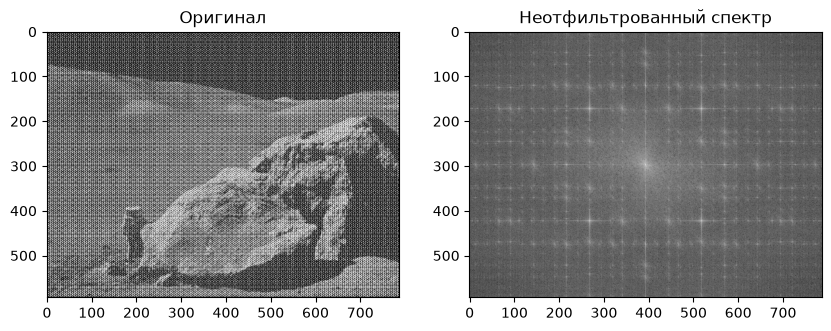

In [13]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap = 'gray'); ax[0].set_title('Оригинал')
ax[1].imshow(magnitude_spectrum, cmap = 'gray'); ax[1].set_title('Неотфильтрованный спектр')

#### Создание и вывод маски на основе ядра Гаусса

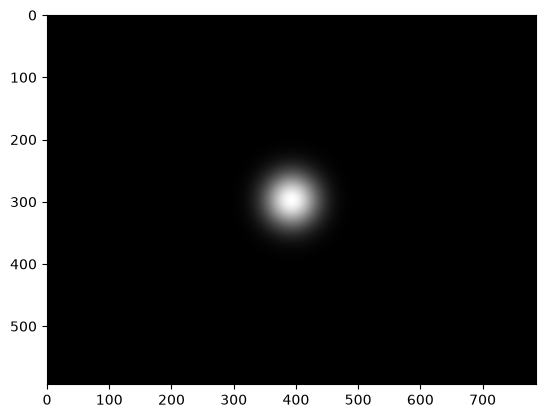

In [14]:
sigma = 30
rows, cols = img.shape
x, y = np.meshgrid(np.arange(0, cols, 1), np.arange(0, rows, 1))

gauss_mask = np.exp(-((x - (cols // 2))**2 + (y - (rows // 2))**2) / (2 * sigma**2))
plt.imshow(gauss_mask, cmap='gray')

#### После фильтрации

Text(0.5, 1.0, 'Отфильтрованный спектр')

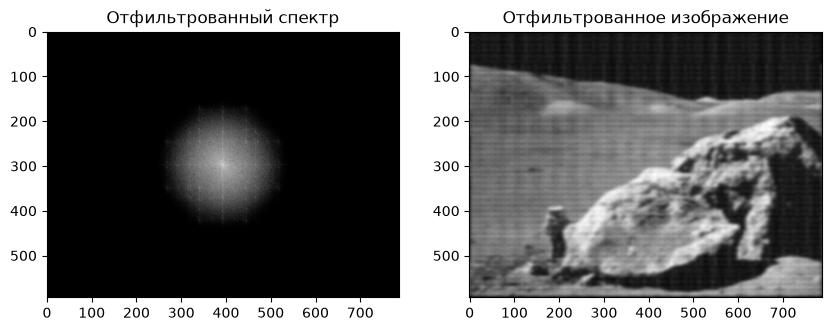

In [15]:
dft_shift_filtered = dft_shift * gauss_mask[:, :, np.newaxis]

magnitude_spectrum_filtered = 20*np.log(cv.magnitude(dft_shift_filtered[:,:,0], dft_shift_filtered[:,:,1]) + 1)

f_ishift = np.fft.ifftshift(dft_shift_filtered)
img_filtered = cv.idft(f_ishift)
img_filtered = cv.magnitude(img_filtered[:,:,0], img_filtered[:,:,1])

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[1].imshow(img_filtered, cmap = 'gray'); ax[1].set_title('Отфильтрованное изображение')
ax[0].imshow(magnitude_spectrum_filtered, cmap = 'gray'); ax[0].set_title('Отфильтрованный спектр')

### 2. Реализуйте вычисление свертки с помощью преобразования Фурье

#### Создание функции для линейной свертки

In [16]:
def fft_convolve(img, kernel):
    ih, iw = img.shape
    kh, kw = kernel.shape
    fh, fw = ih + kh - 1, iw + kw - 1

    F_img    = np.fft.fft2(img.astype(np.float32),    s=(fh, fw))
    F_kernel = np.fft.fft2(kernel.astype(np.float32), s=(fh, fw))

    full = np.real(np.fft.ifft2(F_img * F_kernel))

    ph, pw = kh // 2, kw // 2
    return full[ph:ph+ih, pw:pw+iw]

kernel_5 = np.ones((5, 5), np.float32) / 25
kernel_11 = np.ones((11, 11), np.float32) / 121

#### Применение

Text(0.5, 1.0, 'Свертка с усредняющим ядром 11x11')

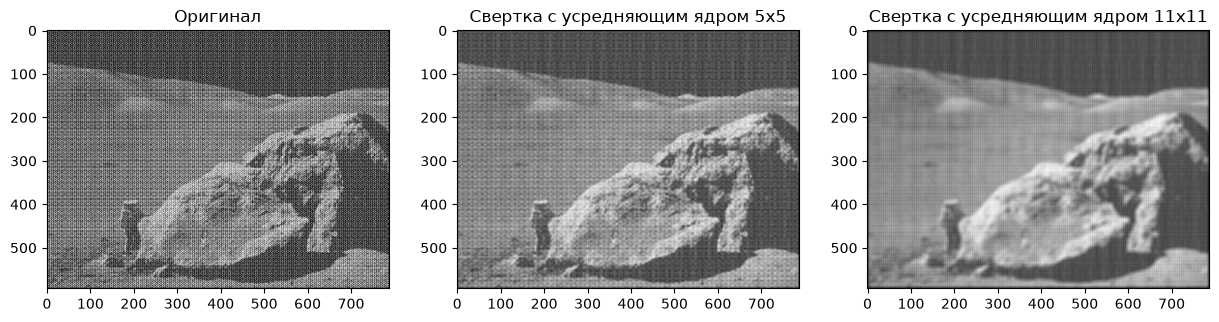

In [17]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)
img_k5_fft = fft_convolve(img, kernel_5)
img_k11_fft = fft_convolve(img, kernel_11)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img, cmap = 'gray'); ax[0].set_title('Оригинал')
ax[1].imshow(img_k5_fft, cmap = 'gray'); ax[1].set_title('Свертка с усредняющим ядром 5x5')
ax[2].imshow(img_k11_fft, cmap = 'gray'); ax[2].set_title('Свертка с усредняющим ядром 11x11')

### 3. Реализуйте удаление периодического шума с помощью преобразования Фурье

In [56]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude_spectrum = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]))

mask = np.ones((img.shape[0], img.shape[1], 2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2), int(img.shape[1] / 2))

highs = np.argwhere(magnitude_spectrum > 240)
for x, y in highs:
    if (x - centerX)**2 + (y - centerY)**2 > 25**2:
        mask[x-3:x+4, y-3:y+4, :] = 0

In [57]:
dft_shift = dft_shift * mask
filtering_magn_res = 20*np.log(cv.magnitude(dft_shift[:,:,0],dft_shift[:,:,1]) + 1)

In [58]:
f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift)
img_back = cv.magnitude(img_back[:,:,0], img_back[:,:,1])

Text(0.5, 1.0, 'Отфильтрованное изображение')

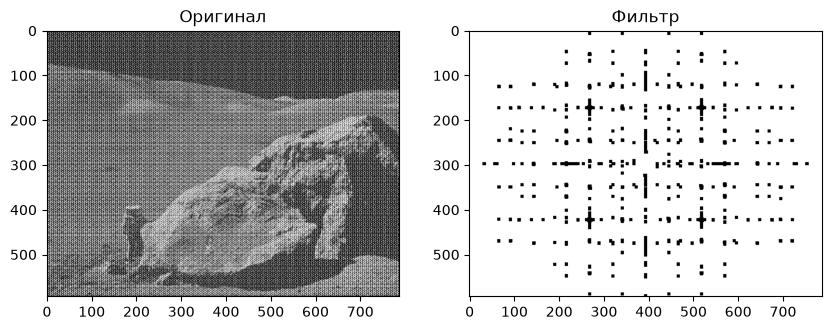

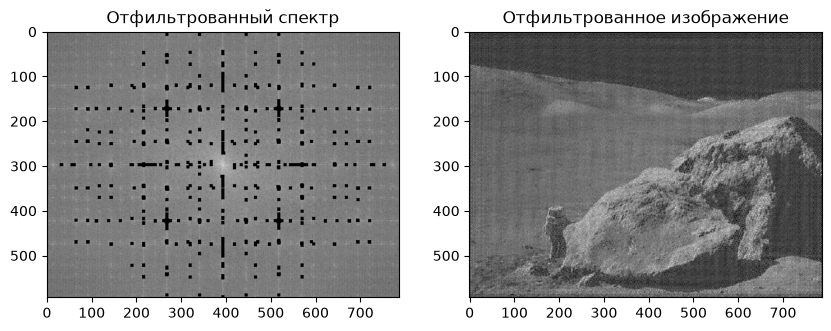

In [59]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap = 'gray'); ax[0].set_title('Оригинал')
ax[1].imshow(mask[:,:,0], cmap = 'gray'); ax[1].set_title('Фильтр')
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(filtering_magn_res, cmap = 'gray'); ax[0].set_title('Отфильтрованный спектр')
ax[1].imshow(img_back, cmap = 'gray'); ax[1].set_title('Отфильтрованное изображение')